In [28]:
import numpy as np
import warnings
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import time
import pickle
from matplotlib.patches import Rectangle

In [29]:
####### replication only, binomial segregation ############
##################################################
class cell:
    def __init__(self,index,init_clusters,parent,birth,tau):
        '''Initializes cell attributes
        param:: index: cell index
        param:: clusters: count of n-clusters
        param:: x: plasmid trajectory in time 
        param:: t: time stamps for x
        param:: parent: parent cell
        param:: birth: birth time
        return:: None
        '''
        self.index=index
        self.init_clusters=init_clusters
        self.fin_clusters=[]
        self.x = []
        self.t = []
        self.parent = parent
        self.birth = birth
        self.div = birth+tau

def pop_check(cells,T):
    b_filter = [x for x in cells if x.t[0] <= T]
    d_filter = [x for x in b_filter if x.t[-1] >T]
    return d_filter #N_pop


def time_approx(s,xi,y_tot,eps):
    D=k_tr*xi
    V=V0*np.exp(mu*s)
    C=K*y_tot/(s0*6.022e2*n)
    a_prime = (mu*n*D*C/V)*(1+C/V)**(-n-1)
    a = D/(1+C/V)**n 
    return (-a+np.sqrt(a**2-2*a_prime*np.log(eps)))/a_prime


def ssa_vol(y0, x0, tau, beta, gamma, sigma, max_size):
    t_x = [0.0]
    x = [x0]

    while True:
        epsilon = np.random.uniform(0, 1)

        t_j = time_approx(
            t_x[-1],
            x[-1],
            x[-1],
            epsilon
        )

        t_next = t_x[-1] + t_j

        if t_next > tau:
            break

        t_x.append(t_next)
        x.append(x[-1] + 1)

    y = np.zeros(max_size)
    y[0] = x[-1]

    return y, np.asarray(x), np.asarray(t_x)

def sim_cells(current,beta,gamma,sigma,max_size):
    y0 = current.init_clusters
    y0[1]=y0[0]
    x0 = np.dot(np.arange(1,max_size),y0[1:max_size])
    y0[1]=0 
    if x0>0:
        yy,xx,tt = ssa_vol(y0,x0,current.div-current.birth,beta,gamma,sigma,max_size)
    else:
        yy = y0
        xx = np.array([0,0])
        tt = np.array([0,current.div-current.birth])
        clust = np.zeros(max_size)
        ty = np.array([0,current.div-current.birth])
    return yy,xx,tt

def lineage_sim(c,tau,beta,gamma,sigma,max_size):
    Line=[]
    current_cell = c 
    N=0
    length = 1
    status =1
    while status == 1:
        #print('############## new cell ##############')
        
        zz0 = np.copy(current_cell.init_clusters) 
        yy,xx,tt= sim_cells(current_cell,beta,gamma,sigma,max_size)
        current_cell.fin_clusters = yy
        current_cell.x = xx
        current_cell.t = tt+current_cell.birth  
        current_cell.init_clusters = zz0
        Line.extend([current_cell])

        rand = np.random.binomial(xx[-1],0.5,1)[0]
        if np.random.uniform(0,1,1)<0.5:
            x0 = rand
        else:
            x0= xx[-1]-rand
        
        yy=np.zeros(max_size)
        yy[0]=x0

        daughter = cell(N+1,yy,current_cell.index,current_cell.div,tau)
        
        if current_cell.x[-1]==x0 or x0==0 or length==5000:
            status = 0
        else:
            length+=1
            status = 1
            current_cell = daughter
            N+=1
    return Line

In [30]:
##################################################
n =  2.56  
s0 = 0.034   
tau =30 #60 #40  #24          #30-min doubling time
k_tr =2.17 #2.73 #2.84  #2.17       
K = 15.8/1.26 #11.35/1.26 #14.5/1.26 #15.8/1.26  
mu = np.log(2)/tau
V0 = 1.2 #0.48 #0.8  #1.2
rho = 0.13

x0=25          #number of plasmids in the initial cell
max_size=200   #total number of possible clusters, can be increased to accomodate larger sims

true_beta = 0.015
true_sigma = 0.08
true_gamm = 0.05

##################################################

warnings.filterwarnings('ignore')
repeats = 1
loss = np.zeros(repeats)
start_time = time.perf_counter()
for k in range(repeats):
    y0 = np.zeros(2*max_size)
    y0[0]=x0
    c= cell(0,y0,[],0,tau)   #index,clusters,parent,birth
    Line = lineage_sim(c,tau,true_beta,true_gamm,true_sigma,max_size)
print('Loss prob',np.mean(loss),'err',np.std(loss))
end_time = time.perf_counter()
elapsed_time = end_time - start_time
print("Elapsed time: ", elapsed_time)
file_name = 'replication.pkl'
with open(file_name, 'wb') as file:
    pickle.dump(Line, file)

Loss prob 0.0 err 0.0
Elapsed time:  1.436116500000935


In [52]:
from pick_cells import cell
with open('replication.pkl', 'rb') as file:
    Line_rep = pickle.load(file)

with open('cluster.pkl', 'rb') as file:
    Line_clu = pickle.load(file)
    

In [53]:
init_x_r = [p.x[0] for p in Line_rep] 
fin_x_r = [p.x[-1] for p in Line_rep] 
init_x_c = [p.x[0] for p in Line_clu] 
fin_x_c = [p.x[-1] for p in Line_clu] 

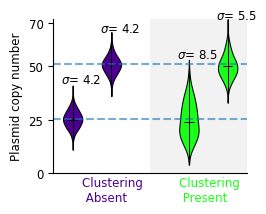

In [56]:
import matplotlib
col = ["#1AFF1A", "#4B0092"]
fontsiz = 8.5

tag1 = '1'
tag2 = '2'
tag3 = '3'
tag4 = '4'
tag5 = '5'

pal = {
    tag1: col[1],
    tag2: col[1],
    tag3: col[1],
    tag4: col[0],
    tag5: col[0]
}

# --------------------------------------------------
# DATAFRAME CONSTRUCTION (UNCHANGED)
# --------------------------------------------------
a1 = pd.DataFrame(init_x_r, columns=[1]).assign(models=tag1)
a2 = pd.DataFrame(fin_x_r, columns=[1]).assign(models=tag2)
a3 = pd.DataFrame([], columns=[1]).assign(models=tag3)  # spacer
a4 = pd.DataFrame(init_x_c, columns=[1]).assign(models=tag4)
a5 = pd.DataFrame(fin_x_c, columns=[1]).assign(models=tag5)

a = pd.concat([a1, a2, a3, a4, a5])
order = [tag1, tag2, tag3, tag4, tag5]

# --------------------------------------------------
# FIGURE
# --------------------------------------------------
f, ax = plt.subplots(figsize=(2.5, 2))

matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

positions = np.arange(len(order))
data_groups = []
valid_positions = []
valid_tags = []

for i, tag in enumerate(order):
    vals = a.loc[a['models'] == tag, 1].dropna().values
    if len(vals) == 0:
        continue  # keep spacing but skip drawing
    data_groups.append(vals)
    valid_positions.append(positions[i])
    valid_tags.append(tag)

vp = ax.violinplot(
    data_groups,
    positions=valid_positions,
    widths=0.5,
    bw_method=0.3,      # seaborn-like smoothing
    showmeans=False,
    showmedians=True,
    showextrema=True
)

for body, tag in zip(vp['bodies'], valid_tags):
    body.set_facecolor(pal[tag])
    body.set_edgecolor('black')
    body.set_linewidth(0.75)
    body.set_alpha(1)

vp['cmedians'].set_color('black')
vp['cmins'].set_visible(False)
vp['cmaxes'].set_visible(False)
vp['cbars'].set_color('black')
vp['cbars'].set_linewidth(0.75)
vp['cmedians'].set_linewidth(0.75)

ax.set_ylim([30, 72])
ax.set_xlim([-0.5, 4.5])
ax.set_ylabel('Plasmid copy number', fontsize=fontsiz)
ax.set_xlabel(' ')
ax.set_yticks([0, 25, 50, 70])
ax.set_xticks([])
ax.set_xticklabels([])
ax.add_patch(Rectangle((2, 0), 3, 72,facecolor='grey',alpha=0.1,zorder=0))
ax.text(0.25, -13, 'Clustering \n Absent',color=col[1], fontsize=fontsiz)
ax.text(2.75, -13, 'Clustering \n Present',color=col[0], fontsize=fontsiz)

# --------------------------------------------------
# GROUND TRUTH LINES
# --------------------------------------------------
ax.hlines(51, -0.5, 4.5,color='C0', linestyle='--', alpha=0.6)
ax.hlines(51/2, -0.5, 4.5,color='C0', linestyle='--', alpha=0.6)

ax.text(-0.3, 42,r'$\sigma$= %1.1f' % np.std(init_x_r),fontsize=fontsiz)
ax.text(0.7, 66,r'$\sigma$= %1.1f' % np.std(fin_x_r),fontsize=fontsiz)
ax.text(2.7, 54,r'$\sigma$= %1.1f' % np.std(init_x_c),fontsize=fontsiz)
ax.text(3.7, 72,r'$\sigma$= %1.1f' % np.std(fin_x_c),fontsize=fontsiz)

ax.tick_params(axis='both', which='major', labelsize=fontsiz)

sns.despine()

plt.savefig("cluster_absent_present.pdf",format="pdf",bbox_inches="tight")

In [57]:
import numpy as np
import pandas as pd


def variance_at_age(Line_rep, ages):
    results = []

    for age in ages:
        values = []

        for cell in Line_rep:

            # Convert absolute time to cell age
            t = np.asarray(cell.t) - cell.birth
            x = np.asarray(cell.x)

            # Cell must have reached this age
            if age <= t[-1]:
                # Copy number immediately before the specified age
                j = np.searchsorted(t, age, side="right") - 1

                if j >= 0:
                    values.append(x[j])

        values = np.asarray(values)

        mean = np.mean(values)
        variance = np.var(values, ddof=1)
        cv = np.sqrt(variance) / mean

        results.append({
            "age": age,
            "n_cells": len(values),
            "mean": mean,
            "variance": variance,
            "CV": cv
        })

    return pd.DataFrame(results)


ages = np.linspace(0, 30, 100)

variance_df = variance_at_age(Line_rep, ages)

print(variance_df)

          age  n_cells     mean   variance        CV
0    0.000000     5000  25.3572  17.253059  0.163807
1    0.303030     5000  25.5384  17.112348  0.161980
2    0.606061     5000  25.7142  17.095938  0.160795
3    0.909091     5000  25.8948  17.014736  0.159294
4    1.212121     5000  26.0788  16.983987  0.158027
..        ...      ...      ...        ...       ...
95  28.787879     5000  48.3508  16.977535  0.085218
96  29.090909     5000  48.6844  17.047006  0.084807
97  29.393939     5000  49.0240  17.172859  0.084530
98  29.696970     5000  49.3628  17.284233  0.084222
99  30.000000     5000  49.7062  17.334148  0.083761

[100 rows x 5 columns]


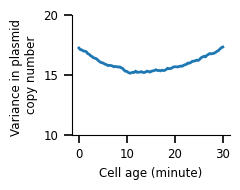

In [58]:
f, ax = plt.subplots(figsize=(2.5, 2))
fontsiz= 8.5
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
plt.tick_params(axis="both", labelsize=fontsiz, length=6, width=1.2)

ax.plot(variance_df["age"], variance_df["variance"], linewidth=2)
ax.set_xlabel("Cell age (minute)",fontsize=fontsiz)
ax.set_ylabel("Variance in plasmid \ncopy number",fontsize=fontsiz)
ax.set_ylim([10,20])
ax.set_yticks([10,15,20])
ax.set_yticklabels([10,15,20])
#ax.set_title("Plasmid copy-number variance over the cell cycle",fontsize=fontsiz)
plt.tight_layout()
sns.despine()
plt.savefig("no_cluster_variance_vs_age.pdf",format="pdf",bbox_inches="tight")
plt.savefig("no_cluster_variance_vs_age.png",format="png",bbox_inches="tight")


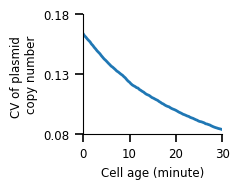

In [67]:
f, ax = plt.subplots(figsize=(2.5, 2))
fontsiz= 8.5
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
plt.tick_params(axis="both", labelsize=fontsiz, length=6, width=1.2)

ax.plot(variance_df["age"], variance_df["CV"], linewidth=2)
ax.set_xlabel("Cell age (minute)",fontsize=fontsiz)
ax.set_ylabel("CV of plasmid \ncopy number",fontsize=fontsiz)
ax.set_ylim([0.08,0.18])
ax.set_yticks([0.08,0.13,0.18])
ax.set_yticklabels([0.08,0.13,0.18])
ax.set_xlim([0,30])
#ax.set_title("Plasmid copy-number variance over the cell cycle",fontsize=fontsiz)
plt.tight_layout()
sns.despine()
plt.savefig("no_cluster_cv_vs_age.pdf",format="pdf",bbox_inches="tight")
plt.savefig("no_cluster_cv_vs_age.png",format="png",bbox_inches="tight")


In [ ]:
plt.savefig("no_cluster.pdf",format="pdf",bbox_inches="tight")